# Programa 9. Validación cruzada K-Fold aplicada al dataset Iris

Noviembre 15, 2026

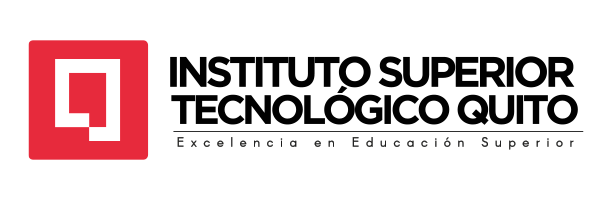

**Nombre:** Edgar Ulloa  
**Fecha:** *15-11-2026*    
**Link Repositorio:** https://github.com/eulloaitq/Fundamentos-de-Machine-Learning.git

## Validación cruzada K-Fold aplicada al dataset Iris

**Objetivo:** Aplicar la validación cruzada **K-Fold** para evaluar un clasificador **SVC** con datos reales, para esto se reserva un conjunto de prueba mediante **Hold-Out**, para luego utilizar K-Fold sobre los datos de entrenamiento logrando de este modo estimar el rendimiento del modelo y finalmente se entrena el clasificador con todos los datos de entrenamiento y se comprueba su capacidad para clasificar las flores Iris.

## Importación de las librerías

Las librerías son porciones de código que proporcionan funciones útiles para trabajar con los datos y modelos de Machine Learning.

- **numpy (np):** Librería que permite realizar operaciones numéricas sobre arreglos o matrices.
- **datasets:** Espacio de memoria que permite cargar los conjuntos de datos de ejemplo, como Iris.
- **DummyClassifier:** Código que sirve como un clasificador de referencia importado en el código.
- **cross_val_score:** Código utilizado para entrenar y evalúar el clasificador de manera repetida de acuerdo a cantidad de particiones de la validación cruzada.
- **KFold:** Código utilizado para definir cómo se dividen los datos en *k* grupos o bolsas (folds).
- **train_test_split:** Código utilizado para separar los datos en conjuntos de entrenamiento y de prueba.
- **StandardScaler:** Código para estandarizar los atributos numéricos de modo que sus escalas se vuelvan comparables.

In [3]:
import numpy as np
from sklearn import datasets
from sklearn.model_selection import cross_val_predict, cross_validate, cross_val_score
from sklearn.model_selection import KFold
from sklearn.model_selection import standarScaler
import sklearn.metrics as metrics
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.pipeline import Pipeline
from pprint import pprint
from sklearn.base import clone
from sklearn.svm import SVC

ImportError: cannot import name 'standarScaler' from 'sklearn.model_selection' (C:\Users\edgar\anaconda3\envs\FundamentosMachineLearningITQ\Lib\site-packages\sklearn\model_selection\__init__.py)

## Carga del dataset Iris

El **dataset Iris** contiene 150 instancias de flores, que se dividen en cuatro atributos numéricos: largo y ancho del sépalo, y largo y ancho del pétalo, tambien contiene observaciones que pertenecen a tres clases de flores, estas son: setosa, versicolor y virginica.

Para realziar la carga del dataset se utiliza la función datasets.load_iris() que carga los datos y sus etiquetas, la función iris.target_names contiene los nombres de las tres clases que se muestran en la pantalla usando el comando print().

In [2]:
# Carga de datos.
iris = datasets.load_iris()
print(iris.target_names)

['setosa' 'versicolor' 'virginica']


Se identifican las especies que el modelo aprenderá a clasificar.

## Exploración de los datos

Antes de entrenar el algoritmo, se debe comprobar ciertos datos como el tamaño del dataset y los valores posibles de la clase objetivo, para ejecutar este proceso se utilizan las siguientes funciones:
- **iris.data:** Obtiene la matriz que contiene las características de las flores.
- **iris.data.shape:** Indica las dimensiones de la matriz; aqui **shape[0]** corresponde al número de instancias y **shape[1]** al número de atributos.
- **iris.target:** Obtiene las etiquetas numéricas de las especies.
- **set(iris.target):** Devuelve los valores de las clases diferentes sin repetirlas.

In [3]:
# Mostrar características de la tabla de datos.
print("Tabla de datos: %d instancias y %d atributos" % (iris.data.shape[0], iris.data.shape[1]))
print("Valores de la clase:", set(iris.target))

Tabla de datos: 150 instancias y 4 atributos
Valores de la clase: {np.int64(0), np.int64(1), np.int64(2)}


Se muestran 150 instancias, 4 atributos y las clases 0, 1 y 2 como int64.

## Partición externa Hold-Out: entrenamiento y prueba

El método **Hold-Out** separa una parte de los datos para que no se use en el proceso de entrenamiento del modelo, en este ejercicio se reserva el 20% para pruebas y se utiliza el 80% para el entrenamiento.

En esta sección se utilizan los siguientes códigos:
- **train_test_split(X, y, ...):** Función que divide simultáneamente los atributos y sus etiquetas.
- **test_size=0.2:** Parametro que reserva el 20% para prueba en este ejercicio.
- **random_state=42:** Parametro que permite reproducir la misma separación al volver a ejecutar el programa.
- **X_train, y_train:** Almacena los atributos y etiquetas para el proceso de entrenamiento.
- **X_test, y_test:** Almacena los atributos y etiquetas reservados para la evaluación final.

In [4]:
# Test: hold-out split 80-20%. PARTICIÓN EXTERNA
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.2, random_state=42)

De las 150 flores que contiene el dataset, 120 se utilizan para el entrenamiento y 30 se reservan para la prueba final.

## Estandarización de las características

El proceso de estandarización sirve para transformar los atributos para que sus escalas sean comparables, es importante sobre todo en algoritmos como SVC, cuyo comportamiento depende de las distancias entre sus observaciones.

Se utiliza las siguientes funciones:
- **StandardScaler():** Codigo que crea el objeto encargado de la estandarizarización.
- **fit_transform(X_train):** Función que calcula la media y la desviación estándar de los datos de entrenamiento y los transforma.
- **transform(X_test):** Función que sirve para aplicar al conjunto de prueba la transformación aprendida, sin que calcule nuevos parámetros con esos datos.

In [5]:
# Estandarizar las características de entrenamiento y de test
standardizer = StandardScaler()
X_train = standardizer.fit_transform(X_train)
X_test = standardizer.transform(X_test)

## Configuración del SVC y validación cruzada K-Fold

**SVC (*Support Vector Classifier*)** es un algoritmo de aprendizaje supervisado diseñado para separar las clases mediante fronteras de decisión.

El código utilizado se detalla a continuación:
- **SVC(C=0.5, gamma='auto'):** Función que crea el clasificador. En este el parametro **C** controla la penalización por errores y el parametro **gamma** influye en el alcance de cada observación para el núcleo RBF (función matemática utilizada por el algoritmo SVC que permite identificar relaciones no lineales entre los datos) usado por defecto.
- **KFold(n_splits=5, shuffle=True, random_state=42):** Función que divide los 120 datos de entrenamiento en cinco bolsas, mezclando previamente las instancias de manera reproducible.
- **cross_val_score(s vc, X_train, y_train, cv=...):** Función que entrena y evalúa un nuevo modelo en cada iteración y devuelve cinco resultados de exactitud.
- **results.mean():** Función que calcula la exactitud media de las cinco iteraciones.
- **results.std():** Función que calcula la desviación estándar, que muestra cuánto varían los resultados entre particiones.

In [14]:
# Definimos el algoritmo SVM para clasificación
from sklearn.svm import SVC
svc = SVC(C=0.5, gamma='auto')

# Hacemos el cross-validation interno para seleccionar los mejores hiperparámetros
results = cross_val_score(svc, X_train, y_train, cv = KFold(n_splits=5, shuffle=True, random_state=42))
print("Resultados por bolsa: ", results)
print("Accuracy (media +/- desv.): %0.4f +/- %0.4f" % (results.mean(), results.std()))

Resultados por bolsa:  [0.95833333 0.95833333 0.83333333 0.95833333 0.95833333]
Accuracy (media +/- desv.): 0.9333 +/- 0.0500


Se debe observar en los resultado que cuanto mayor sea la exactitud media, mejor habrá clasificado el modelo en estas particiones, así mismo una desviación estándar pequeña indica resultados más parecidos entre ellas.

## Entrenamiento del modelo definitivo

Después de realizar la validación cruzada, se entrena el clasificador con las 120 instancias separadas para el entrenamiento, de este modo se aprovechan los datos que durante K-Fold se fueron alternando entre el proceso de entrenamiento y el de validación.

Aqui se utiliza la siguiente funcion:
- **svc.fit(X_train, y_train):** Función que ajusta el modelo SVC utilizando los atributos y sus clases correctas.

In [16]:
# Una vez entrenado y validado el modelo para seleccionar los mejores hyperparameters, utilizamos todos los datos de
# "train" y "val" para entrenar el modelo definitivo

svc = svc.fit(X_train, y_train)

## Evaluación final con el conjunto de prueba

La medida de exactitud **(*accuracy*)** representa la proporción de predicciones correctas obtenidas por el modelo y su fórmula es:

$$\text{Accuracy}=\frac{\text{Número de predicciones correctas}}{\text{Número total de predicciones}}$$

El código utilizado es el siguiente:
- **svc.score(X_test, y_test):** Función que calcula la exactitud del clasificador en las instancias de prueba.
- **test_results * 100:** Parametro que convierte el resultado decimal obtenido en formato de porcentaje.

In [17]:
# Calcular la accuracy del conjunto de test
test_results = svc.score(X_test, y_test)
print('Exactitud en test: ', test_results*100, '%')

Exactitud en test:  100.0 %


El resultado obtenido en un número decimal equivale a su representacion en porcentaje (%) en ese conjunto, aqui el resultado debe leerse como el porcentaje del desempeño sobre estas observaciones de prueba, no como garantía de aciertos con cualquier flor futura.

## Predicciones y comparación con las etiquetas reales

La función **predict(X)** genera una clase estimada para cada observación que recibe.

El código se define así:
- **svc.predict(X_test):** Funcion que obtiene las predicciones del clasificador sobre el conjunto de prueba.
- **y_pred:** Parametro que almacena las clases que predijo el modelo.
- **y_test:** Parametro que contiene las clases verdaderas.

In [9]:
# Extraer las predicciones, en lugar de directamente la accuracy
y_pred = svc.predict(X_test)
print('Predicciones:     ', y_pred)
print('Etiquetas reales: ', y_test)

Predicciones:      [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Etiquetas reales:  [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


Cuando un valor de y_pred coincide con el de y_test en la misma posición, la predicción es correcta; si son diferentes, el modelo se equivocó en esa flor.

## Conclusión

EL proceso de validación cruzada **K-Fold** permite estimar el desempeño de un modelo utilizando diferentes divisiones de los datos, en lugar de depender de una sola partición interna, aqui el conjunto de prueba es útil para realizar una evaluación final independiente, ya que la comparación entre los valores de **y_pred** y **y_test** permite identificar directamente los aciertos y errores del clasificador.